Initial API testing and preliminary EDA on the 24 hour API response

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import json

print("Libraries imported")

Libraries imported


In [2]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.1 (tags/v3.11.1:a7a450f, Dec  6 2022, 19:58:39) [MSC v.1934 64 bit (AMD64)]
Python executable: c:\Users\mahaa\OneDrive\Desktop\AgentWeather\venv\Scripts\python.exe


In [3]:
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Raw data folder:", RAW_DATA_DIR.resolve())

Raw data folder: C:\Users\mahaa\OneDrive\Desktop\AgentWeather\data\raw


In [4]:
# Open-Meteo Weather API
weather_url = "https://api.open-meteo.com/v1/forecast?latitude=31.5580&longitude=74.3507&hourly=temperature_2m,relative_humidity_2m,precipitation_probability,precipitation,uv_index,wind_speed_10m,wind_direction_10m&forecast_days=1&timezone=Asia%2FKarachi"

# Open-Meteo Air Quality API
air_quality_url = "https://air-quality-api.open-meteo.com/v1/air-quality?latitude=31.5580&longitude=74.3507&hourly=us_aqi,european_aqi,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone&forecast_days=1&timezone=Asia%2FKarachi"

weather_response = requests.get(weather_url)
air_quality_response = requests.get(air_quality_url)

weather_response.raise_for_status()
air_quality_response.raise_for_status()

weather_data = weather_response.json()
air_quality_data = air_quality_response.json()

print("Both Meteo API Weather and air quality responses retrieved")

Both Meteo API Weather and air quality responses retrieved


In [5]:
# Save Open-Meteo weather response
with open(RAW_DATA_DIR / "openmeteo_weather_raw.json", "w", encoding="utf-8") as f:
    json.dump(weather_data, f, indent=4)

# Save Open-Meteo air quality response
with open(RAW_DATA_DIR / "openmeteo_air_quality_raw.json", "w", encoding="utf-8") as f:
    json.dump(air_quality_data, f, indent=4)

print("Both Open-Meteo JSON files saved successfully")

Both Open-Meteo JSON files saved successfully


In [6]:
import json

with open(RAW_DATA_DIR / "openmeteo_weather_raw.json", "r", encoding="utf-8") as f:
    weather_raw = json.load(f)

with open(RAW_DATA_DIR / "openmeteo_air_quality_raw.json", "r", encoding="utf-8") as f:
    air_quality_raw = json.load(f)

print("Weather API keys:", weather_raw.keys())
print("Air Quality API keys:", air_quality_raw.keys())

Weather API keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
Air Quality API keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


Inspecting the hourly data

In [7]:
print("WEATHER DATA")
print("-" * 40)

for key, value in weather_raw["hourly"].items():
    print(f"{key}: {len(value)} records")

print("\nAIR QUALITY DATA")
print("-" * 40)

for key, value in air_quality_raw["hourly"].items():
    print(f"{key}: {len(value)} records")

WEATHER DATA
----------------------------------------
time: 24 records
temperature_2m: 24 records
relative_humidity_2m: 24 records
precipitation_probability: 24 records
precipitation: 24 records
uv_index: 24 records
wind_speed_10m: 24 records
wind_direction_10m: 24 records

AIR QUALITY DATA
----------------------------------------
time: 24 records
us_aqi: 24 records
european_aqi: 24 records
pm10: 24 records
pm2_5: 24 records
carbon_monoxide: 24 records
nitrogen_dioxide: 24 records
sulphur_dioxide: 24 records
ozone: 24 records


Converting API responses into DataFrames

In [8]:
weather_df = pd.DataFrame(weather_raw["hourly"])
air_quality_df = pd.DataFrame(air_quality_raw["hourly"])

print("Weather DataFrame:")
display(weather_df.head())

print("\nAir Quality DataFrame:")
display(air_quality_df.head())

Weather DataFrame:


,time,temperature_2m,relative_humidity_2m,precipitation_probability,precipitation,uv_index,wind_speed_10m,wind_direction_10m
0,2026-11-09T00:00,20.2,71,0,0.0,0.0,6.7,84
1,2026-11-09T01:00,19.9,72,0,0.0,0.0,7.0,72
2,2026-11-09T02:00,19.4,73,0,0.0,0.0,6.8,72
3,2026-11-09T03:00,18.9,75,0,0.0,0.0,6.3,77
4,2026-11-09T04:00,18.3,80,0,0.0,0.0,5.1,73



Air Quality DataFrame:


,time,us_aqi,european_aqi,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,2026-11-09T00:00,182,88,115.7,109.4,847.0,60.9,14.4,27.0
1,2026-11-09T01:00,182,84,105.2,100.8,754.0,48.9,12.3,32.0
2,2026-11-09T02:00,181,82,98.0,94.8,705.0,39.5,10.7,35.0
3,2026-11-09T03:00,180,80,92.7,90.3,692.0,34.1,9.7,34.0
4,2026-11-09T04:00,180,78,88.5,86.6,723.0,31.4,9.2,32.0


Data quality inspection

In [9]:
print("WEATHER DATA TYPES")
print(weather_df.dtypes)

print("\nAIR QUALITY DATA TYPES")
print(air_quality_df.dtypes)

print("\nWEATHER MISSING VALUES")
print(weather_df.isnull().sum())

print("\nAIR QUALITY MISSING VALUES")
print(air_quality_df.isnull().sum())

print("\nDUPLICATE WEATHER TIMESTAMPS:")
print(weather_df["time"].duplicated().sum())

print("\nDUPLICATE AIR QUALITY TIMESTAMPS:")
print(air_quality_df["time"].duplicated().sum())


WEATHER DATA TYPES
time                             str
temperature_2m               float64
relative_humidity_2m           int64
precipitation_probability      int64
precipitation                float64
uv_index                     float64
wind_speed_10m               float64
wind_direction_10m             int64
dtype: object

AIR QUALITY DATA TYPES
time                    str
us_aqi                int64
european_aqi          int64
pm10                float64
pm2_5               float64
carbon_monoxide     float64
nitrogen_dioxide    float64
sulphur_dioxide     float64
ozone               float64
dtype: object

WEATHER MISSING VALUES
time                         0
temperature_2m               0
relative_humidity_2m         0
precipitation_probability    0
precipitation                0
uv_index                     0
wind_speed_10m               0
wind_direction_10m           0
dtype: int64

AIR QUALITY MISSING VALUES
time                0
us_aqi              0
european_aqi        0
pm

Converting timestamps to datetime

In [10]:
weather_df["time"] = pd.to_datetime(weather_df["time"])
air_quality_df["time"] = pd.to_datetime(air_quality_df["time"])

print("Weather timestamp type:", weather_df["time"].dtype)
print("Air quality timestamp type:", air_quality_df["time"].dtype)

print("\nWeather time range:")
print(weather_df["time"].min(), "to", weather_df["time"].max())

print("\nAir quality time range:")
print(air_quality_df["time"].min(), "to", air_quality_df["time"].max())

Weather timestamp type: datetime64[us]
Air quality timestamp type: datetime64[us]

Weather time range:
2026-11-09 00:00:00 to 2026-11-09 23:00:00

Air quality time range:
2026-11-09 00:00:00 to 2026-11-09 23:00:00


Checking whether timestamps match

In [11]:
print("Weather and Air Quality timestamps match:",
      weather_df["time"].equals(air_quality_df["time"]))

print("\nWeather timestamps not in Air Quality:")
print(set(weather_df["time"]) - set(air_quality_df["time"]))

print("\nAir Quality timestamps not in Weather:")
print(set(air_quality_df["time"]) - set(weather_df["time"]))

Weather and Air Quality timestamps match: True

Weather timestamps not in Air Quality:
set()

Air Quality timestamps not in Weather:
set()


Merging weather and air-quality data

In [12]:
combined_df = pd.merge(
    weather_df,
    air_quality_df,
    on="time",
    how="inner"
)

print("Combined dataset shape:", combined_df.shape)

display(combined_df.head())

Combined dataset shape: (24, 16)


,time,temperature_2m,relative_humidity_2m,precipitation_probability,precipitation,uv_index,wind_speed_10m,wind_direction_10m,us_aqi,european_aqi,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,2026-11-09 00:00:00,20.2,71,0,0.0,0.0,6.7,84,182,88,115.7,109.4,847.0,60.9,14.4,27.0
1,2026-11-09 01:00:00,19.9,72,0,0.0,0.0,7.0,72,182,84,105.2,100.8,754.0,48.9,12.3,32.0
2,2026-11-09 02:00:00,19.4,73,0,0.0,0.0,6.8,72,181,82,98.0,94.8,705.0,39.5,10.7,35.0
3,2026-11-09 03:00:00,18.9,75,0,0.0,0.0,6.3,77,180,80,92.7,90.3,692.0,34.1,9.7,34.0
4,2026-11-09 04:00:00,18.3,80,0,0.0,0.0,5.1,73,180,78,88.5,86.6,723.0,31.4,9.2,32.0


Descriptive statistical analysis

In [13]:
# Generate descriptive statistics
summary = combined_df.describe().T

display(summary)

,count,mean,min,25%,50%,75%,max,std
time,24,2026-11-09 11:30:00,2026-11-09 00:00:00,2026-11-09 05:45:00,2026-11-09 11:30:00,2026-11-09 17:15:00,2026-11-09 23:00:00,NaN
temperature_2m,24.0,22.0625,17.4,19.325,21.25,25.225,27.3,3.388576
relative_humidity_2m,24.0,67.458333,47.0,61.0,71.5,75.25,84.0,11.628223
precipitation_probability,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
precipitation,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
uv_index,24.0,1.058333,0.0,0.0,0.0,1.95,4.2,1.576986
wind_speed_10m,24.0,4.283333,1.1,2.65,4.55,5.425,7.0,1.805226
wind_direction_10m,24.0,140.5,4.0,67.0,75.0,309.75,360.0,133.292421
us_aqi,24.0,176.791667,173.0,175.0,176.0,178.25,182.0,2.587246
european_aqi,24.0,82.416667,63.0,77.75,81.0,89.0,97.0,9.445112


Verifying the units

In [14]:
print("WEATHER API UNITS")
for column, unit in weather_raw["hourly_units"].items():
    print(f"{column}: {unit}")

print("\nAIR QUALITY API UNITS")
for column, unit in air_quality_raw["hourly_units"].items():
    print(f"{column}: {unit}")

WEATHER API UNITS
time: iso8601
temperature_2m: °C
relative_humidity_2m: %
precipitation_probability: %
precipitation: mm
uv_index: 
wind_speed_10m: km/h
wind_direction_10m: °

AIR QUALITY API UNITS
time: iso8601
us_aqi: USAQI
european_aqi: EAQI
pm10: μg/m³
pm2_5: μg/m³
carbon_monoxide: μg/m³
nitrogen_dioxide: μg/m³
sulphur_dioxide: μg/m³
ozone: μg/m³


visualizing weather variables

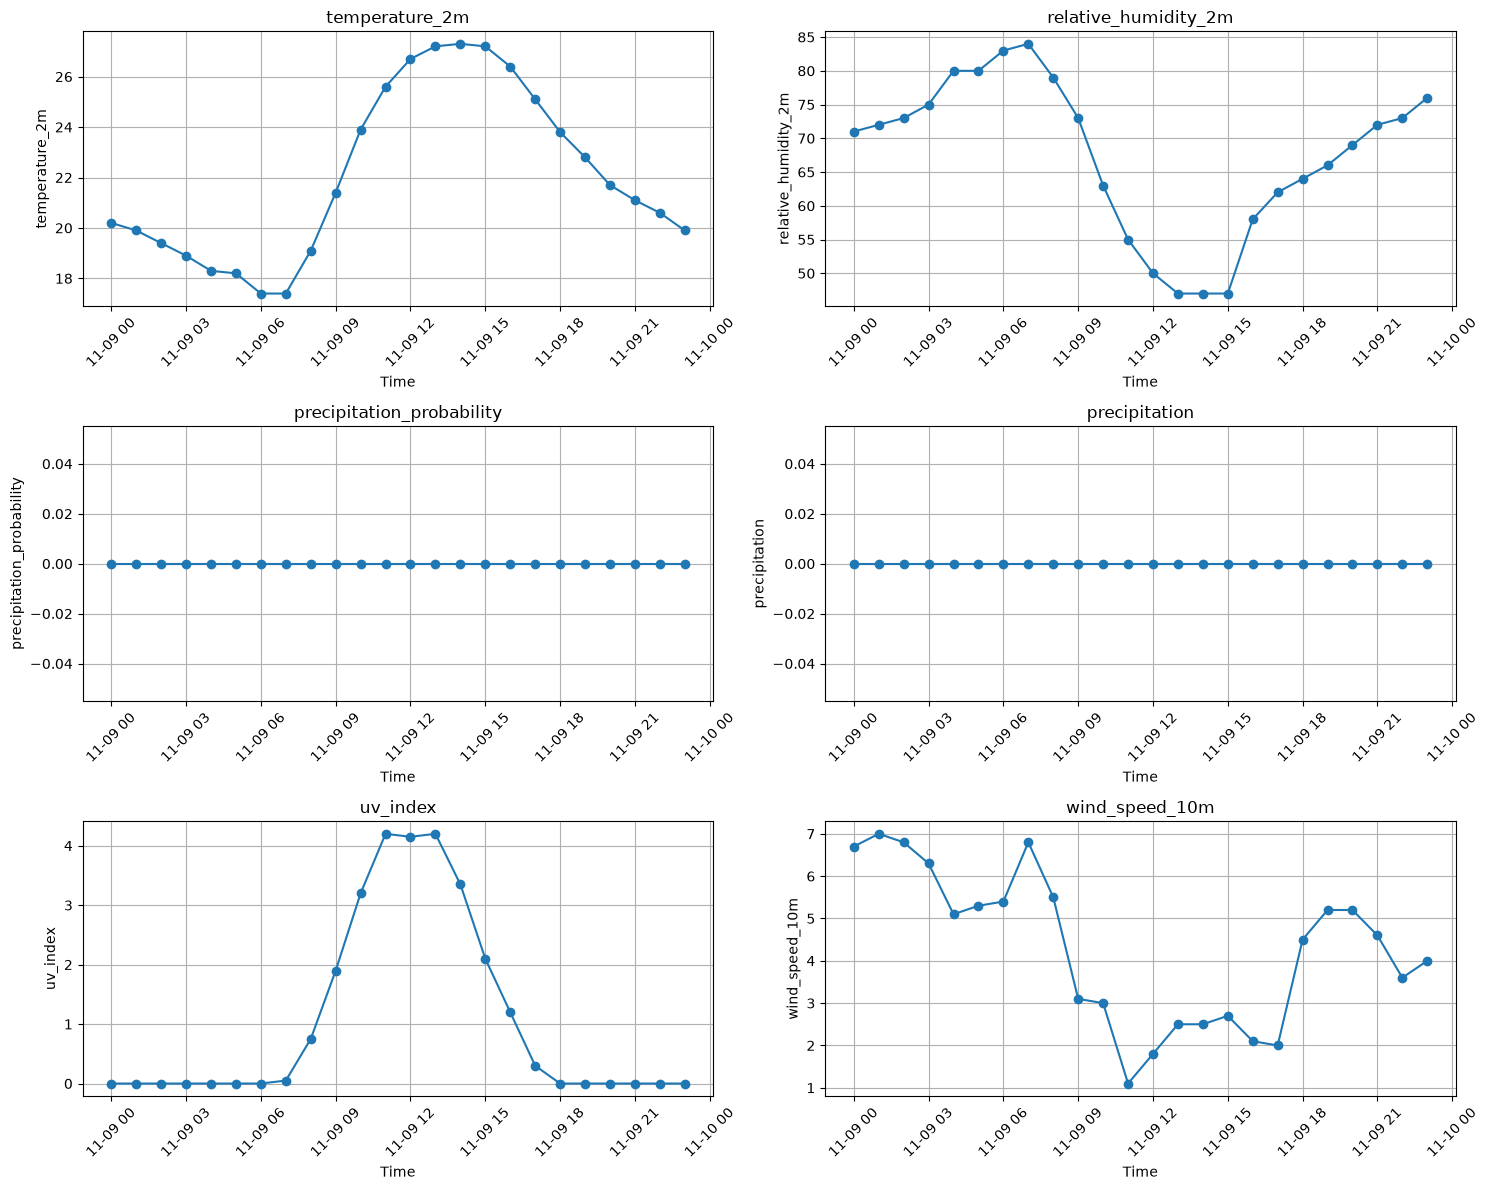

In [15]:
import matplotlib.pyplot as plt

weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_probability",
    "precipitation",
    "uv_index",
    "wind_speed_10m"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for ax, column in zip(axes.flatten(), weather_columns):
    ax.plot(combined_df["time"], combined_df[column], marker="o")
    ax.set_title(column)
    ax.set_xlabel("Time")
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()

Air-quality visualization

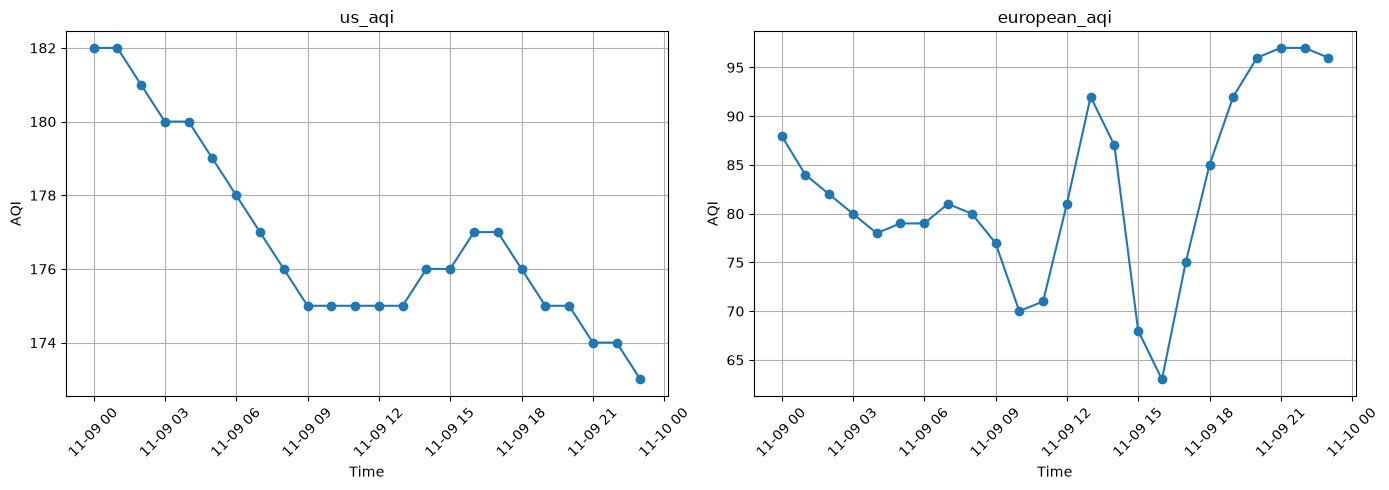

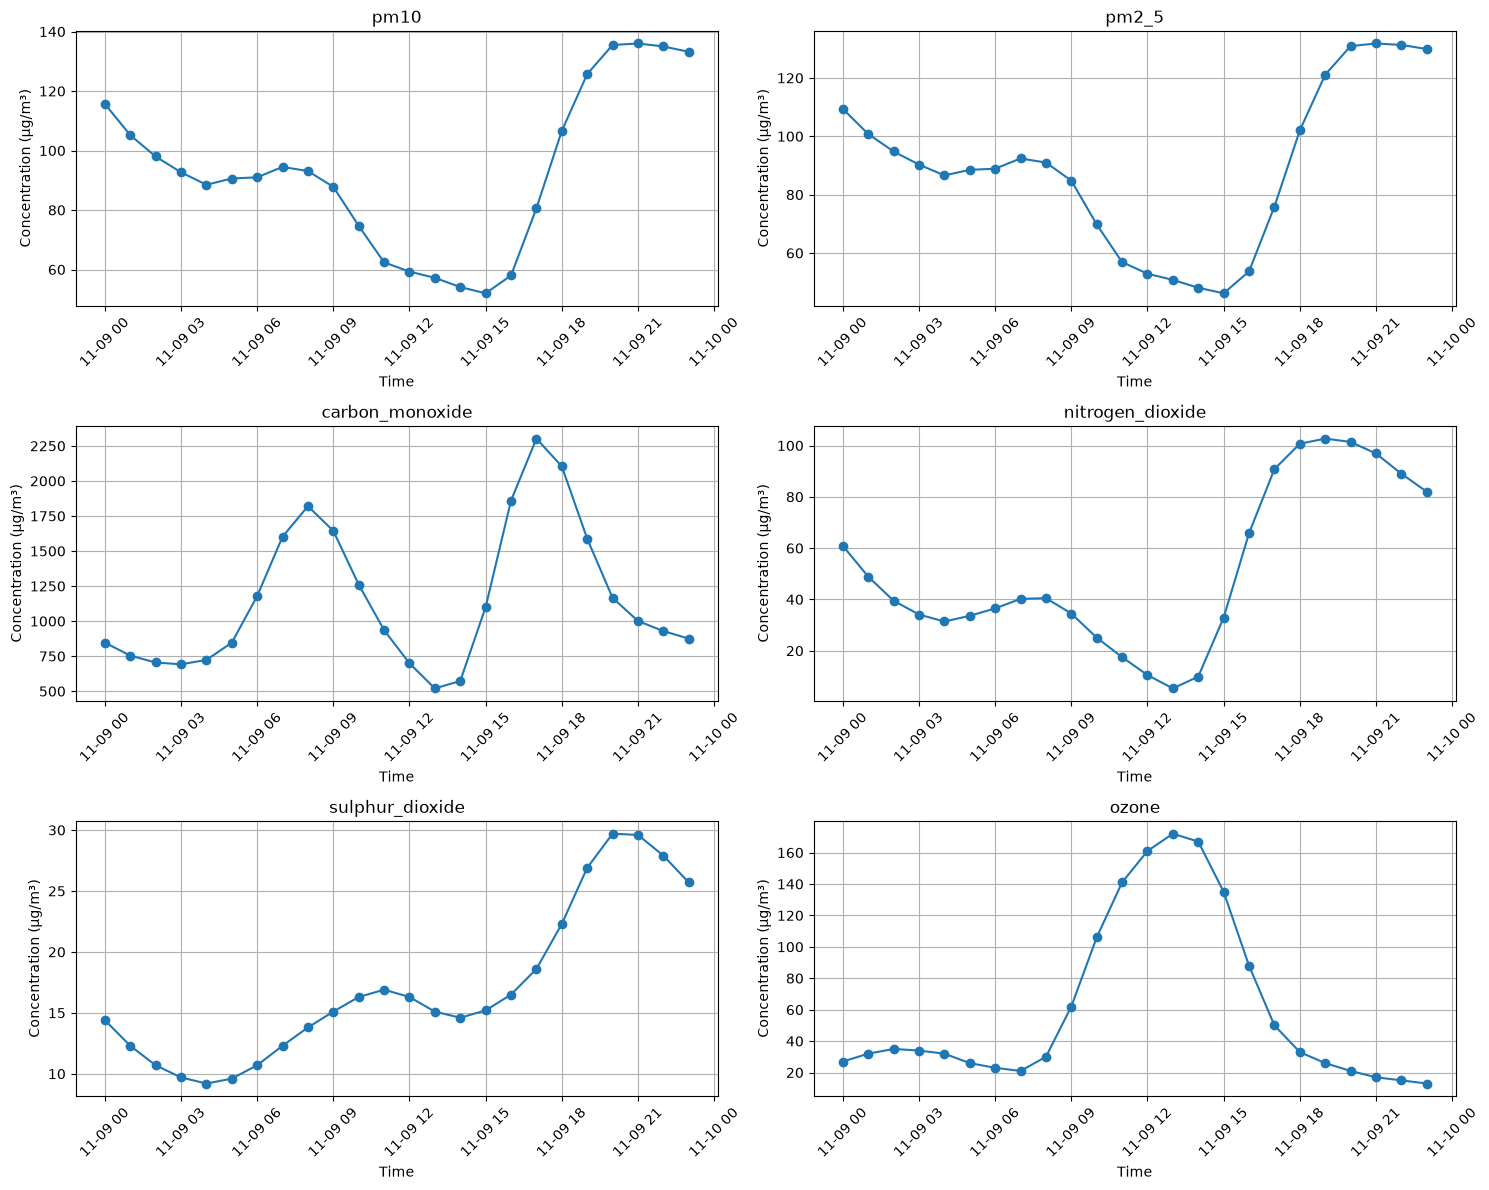

In [16]:
import matplotlib.pyplot as plt

# AQI variables
aqi_columns = ["us_aqi", "european_aqi"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, aqi_columns):
    ax.plot(combined_df["time"], combined_df[column], marker="o")
    ax.set_title(column)
    ax.set_xlabel("Time")
    ax.set_ylabel("AQI")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()


# Pollutant variables
pollutant_columns = [
    "pm10",
    "pm2_5",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for ax, column in zip(axes.flatten(), pollutant_columns):
    ax.plot(combined_df["time"], combined_df[column], marker="o")
    ax.set_title(column)
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration (μg/m³)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()

Correlation analysis

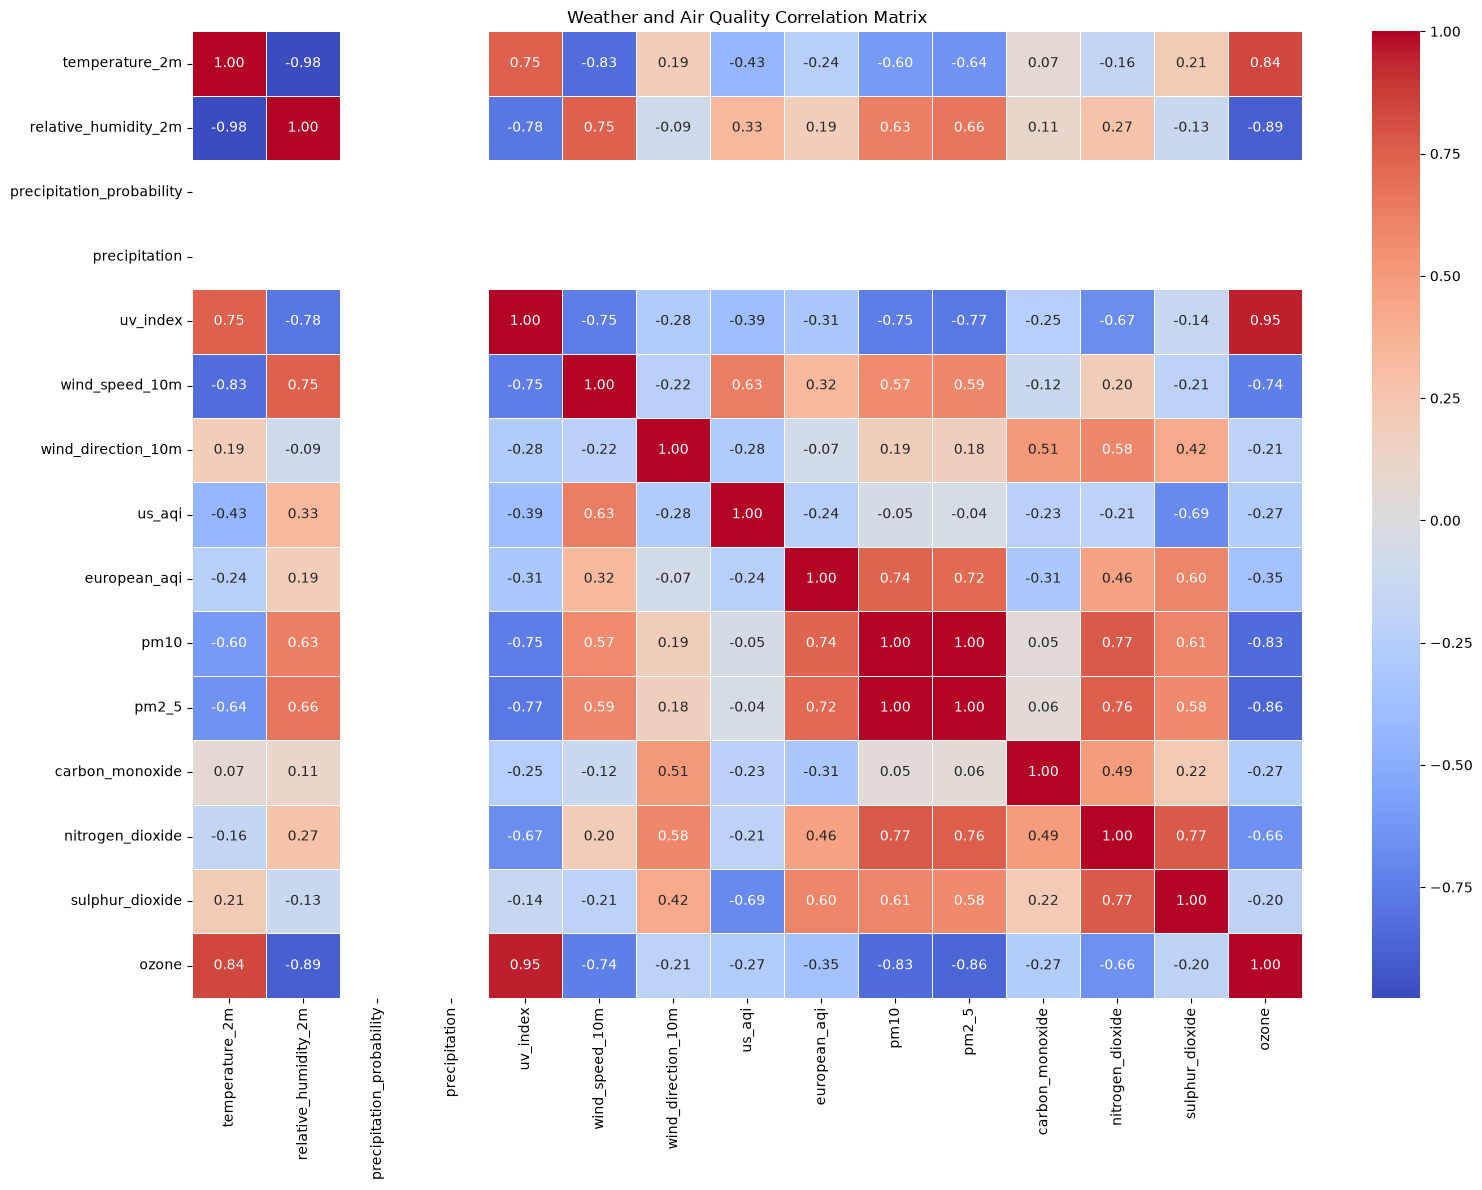

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Exclude time because correlation applies to numerical variables
correlation_matrix = combined_df.drop(columns=["time"]).corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Weather and Air Quality Correlation Matrix")
plt.tight_layout()
plt.show()

Checking valid data ranges

In [18]:
# Define expected valid ranges
valid_ranges = {
    "temperature_2m": (None, None),
    "relative_humidity_2m": (0, 100),
    "precipitation_probability": (0, 100),
    "precipitation": (0, None),
    "uv_index": (0, None),
    "wind_speed_10m": (0, None),
    "wind_direction_10m": (0, 360),
    "pm10": (0, None),
    "pm2_5": (0, None),
    "carbon_monoxide": (0, None),
    "nitrogen_dioxide": (0, None),
    "sulphur_dioxide": (0, None),
    "ozone": (0, None)
}

for column, (lower, upper) in valid_ranges.items():
    invalid = pd.Series(False, index=combined_df.index)

    if lower is not None:
        invalid |= combined_df[column] < lower

    if upper is not None:
        invalid |= combined_df[column] > upper

    print(f"{column}: {invalid.sum()} invalid records")

temperature_2m: 0 invalid records
relative_humidity_2m: 0 invalid records
precipitation_probability: 0 invalid records
precipitation: 0 invalid records
uv_index: 0 invalid records
wind_speed_10m: 0 invalid records
wind_direction_10m: 0 invalid records
pm10: 0 invalid records
pm2_5: 0 invalid records
carbon_monoxide: 0 invalid records
nitrogen_dioxide: 0 invalid records
sulphur_dioxide: 0 invalid records
ozone: 0 invalid records


Checking unique values and variation

In [19]:
# Check the number of unique values in each numerical column

for column in combined_df.drop(columns=["time"]).columns:
    unique_count = combined_df[column].nunique()
    print(f"{column}: {unique_count} unique values")

temperature_2m: 21 unique values
relative_humidity_2m: 18 unique values
precipitation_probability: 1 unique values
precipitation: 1 unique values
uv_index: 11 unique values
wind_speed_10m: 21 unique values
wind_direction_10m: 20 unique values
us_aqi: 10 unique values
european_aqi: 18 unique values
pm10: 24 unique values
pm2_5: 24 unique values
carbon_monoxide: 24 unique values
nitrogen_dioxide: 24 unique values
sulphur_dioxide: 20 unique values
ozone: 21 unique values
